# DNAscape mapping atlas (rmap)

This notebook introduces `rmap`, the DNAscape workflow for mapping between replication features through mathematical relationships derived under explicit mechanistic assumptions. Rather than simulating individual S phases, `rmap` uses deterministic transformations or fitted kinetic quantities to move between features such as origin firing activity, fork speed, replication timing, fork directionality, among others. It is therefore designed for well-defined scenarios in which the supplied data and the target quantity are expected to be linked by a specific modelling assumption.

The notebook is organised by **target feature**: first decide what you want to infer, then provide the data or kinetic quantities needed to infer it. In `rmap`, `source` contains the supplied replication data or model-derived quantities, while `assumptions` contains the settings that define the mapping route, such as `resolution_x`, geometry, target form and fitting controls.

**Data types.** We use replication timing (RT) as the main entry point and consider four targets: origin firing, fork speed, joint kinetic fields and replication timing itself. The arrays used by the model should be interpreted as kinetic representations of the underlying biology, rather than raw assay values. They should therefore be preprocessed according to the biological question being asked. See `1_datamanagement.ipynb` for details on data preparation and formatting.

**Space-time dependence.** When `rmap` is used to infer either `firing_rate` or `fork_speed`, `target_form` specifies the dependency structure of the inferred quantity: `constant` for a single fitted value, `space` for an $x$-dependent profile, `time` for a time-dependent profile and `spacetime` for a full $(x,t)$ field. If `target_form` is omitted, `rmap` defaults to `space` for both targets. 

**Fitting errors.** As the expected RT is uniquely determined from initiation rate and fork speed, the goodness of each fit and mapping is evaluated with the mean square error (MSE) between a reference timing profile and the predicted one.

## Setup

Autoreload keeps notebook runs aligned with source-code edits.

In [13]:
%reload_ext autoreload
%autoreload 2

from dnascape import *

### Inspecting available mappings

`rmap.available()` lists the targets that can be requested.

In [14]:
rmap.available()

,target,description
0,firing_rate,Origin firing activity to infer or supply.
1,fork_speed,Fork progression speed to infer or supply.
2,kinetic_fields,Jointly fitted firing-rate and fork-speed fields.
3,replication_timing,Replication timing along genomic position.
4,fork_directionality,Net fork movement directionality along position.


For a specific target, `rmap.requirements()` shows the source data and assumptions needed to run the corresponding mappings.

In [15]:
rmap.requirements(target="firing_rate")

,
target,firing_rate
source (required data),"replication_timing, fork_speed"
assumptions,"target_form, resolution_x, resolution_t, time_grid, T0, perQ, neighbourhood_range, rate_bounds, fit_step, maxiter, sim_number, fit_step_x, maxiter_x, fit_step_t, maxiter_t, sim_number_t, smoothw_t, fit_step_xt, fit_step_xt_x, fit_step_xt_t, maxiter_xt, sim_number_xt, spacetime_update, kernel_xt_t, err_threshold, deviation_threshold, floor, refine_ratio_bounds, refine_edge_kb, refine_seed, refine_verbose, stall_rate, tau"
target description,Origin firing activity to infer or supply.


The optional views below expose the expected data forms and the meaning of the assumptions.

In [16]:
rmap.requirements(target="firing_rate", show_data=True)

,role,quantity,form,target_form
0,source,replication_timing,array (space-dependent),-
1,source,fork_speed,scalar (constant in space and time),-
2,source,fork_speed,array (space-dependent),-
3,source,fork_speed,transposed array (time-dependent),-
4,source,fork_speed,matrix (space-time dependent),-
5,target,firing_rate,scalar (constant in space and time),constant
6,target,firing_rate,array (space-dependent),space
7,target,firing_rate,transposed array (time-dependent),time
8,target,firing_rate,matrix (space-time dependent),spacetime


In [17]:
rmap.requirements(target="firing_rate", explain_assumptions=True)

,assumption,default,description
0,target_form,space,"Requested output form: scalar (constant in space and time), array (space-dependent), transposed array (time-dependent), or matrix (space-time dependent)."
1,resolution_x,1.0,"Spatial resolution along the genome, in kb."
2,resolution_t,1.0,"Temporal resolution, in minutes."
3,time_grid,None,Explicit time axis to use for time-dependent fields.
4,T0,None,Reference start time used when converting timing values to a relative time axis.
5,perQ,False,Whether the genome is treated as periodic/circular.
6,neighbourhood_range,2000,"Spatial range, in kb, used by deterministic neighbourhood mappings."
7,rate_bounds,None,Allowed lower and upper bounds for scalar firing-rate fitting.
8,fit_step,0.6,"Global multiplicative update size for the active fitting phase; fit_step_x, fit_step_t, or fit_step_xt override it for specific phases."
9,maxiter,10,"Global iteration count for the active fitting phase; maxiter_x, maxiter_t, or maxiter_xt override it for specific phases."


## Example data

We use the hESC chromosome 1 replication-timing profile as an example for `rmap` usage. The selected profile is a one-dimensional `T(x)` array, and `positions_kb` gives the matching genomic coordinates. Here, we consider data at a 1-kilobase resolution.

In [18]:
chr_number = 1
interval_kb = (0, 60_000)

replication_timing_full = loadcsv(
    "example",
    example="replication_timing_hESC",
    chr_number=chr_number,
)

replication_timing, positions_kb = select_profile_region(
    replication_timing_full,
    interval_kb=interval_kb,
)

n_positions = replication_timing.size

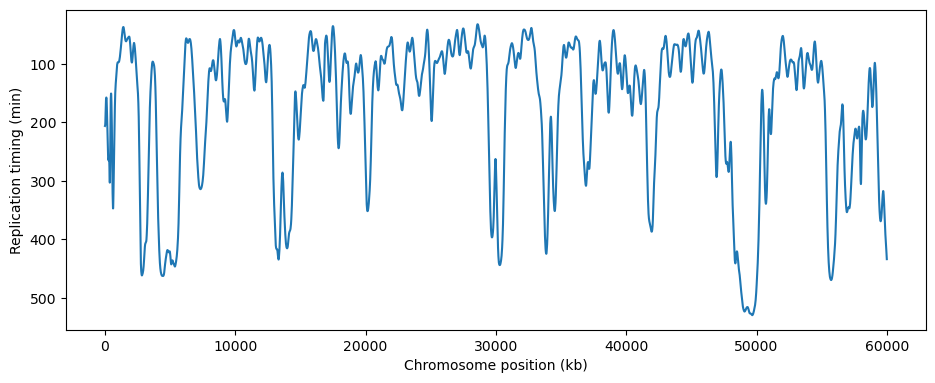

In [19]:
plotf(
    replication_timing,
    x_array=positions_kb,
    invyQ=True,
    xtitle="Chromosome position (kb)",
    ytitle="Replication timing (min)",
)

## Core mapping routes (dev only)

In [20]:
rmap.development()

,target,required data,data forms,required assumptions,optional assumptions,assumption forms,assumption values,method,status,description
0,replication_timing,"firing_rate, fork_speed",firing_rate: scalar/x; fork_speed: scalar/x,-,"resolution_x, neighbourhood_range, perQ, n_bins, genome_length, interval_kb",-,-,firing_and_speed_to_timing_deterministic,implemented,Deterministic mapping for I0 or I(x) with v0 or spatial effective v(x).
1,replication_timing,"firing_rate, fork_speed",firing_rate: scalar/x/t/xt; fork_speed: t/xt,-,"resolution_x, neighbourhood_range, perQ, n_bins, genome_length, interval_kb",-,-,firing_and_variable_speed_to_timing,needs method,Forward timing maps with time-only or space-time fork speed need dedicated methods.
2,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: scalar,target_form,"resolution_x, neighbourhood_range, fit_step, maxiter, err_threshold, rate_bounds, verbose, print_every, perQ, n_bins",-,target_form: constant,timing_and_speed_to_constant_firing_rate,implemented,Scalar fit of I0 from timing and constant fork speed.
3,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: scalar,-,"resolution_x, neighbourhood_range, fit_step, maxiter, sim_number, err_threshold, deviation_threshold, fit_step_x, maxiter_x, verbose, print_every, perQ, stall_rate, tau, target_form",-,target_form: space,timing_and_speed_to_firing_rate,implemented,Iterative fit of I(x) from timing and constant fork speed.
4,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: x/t/xt,target_form,"resolution_x, resolution_t, neighbourhood_range, fit_step, maxiter, sim_number, err_threshold, rate_bounds, refine_seed, verbose, print_every, perQ, n_bins",-,target_form: constant,timing_and_variable_speed_to_firing_rate,implemented,Scalar effective fit of I0 from timing with variable fork speed.
5,firing_rate,"replication_timing, fork_speed",replication_timing: x; fork_speed: x/t/xt,-,"resolution_x, neighbourhood_range, fit_step, maxiter, sim_number, err_threshold, deviation_threshold, fit_step_x, maxiter_x, verbose, print_every, perQ, stall_rate, tau, target_form",-,target_form: space,timing_and_variable_speed_to_spatial_firing_rate,implemented,Space-dependent effective fit of I(x) from timing with variable fork speed.
6,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: scalar/x,-,"resolution_x, neighbourhood_range, fit_step, maxiter, speed_bounds, initial_fork_speed, verbose, print_every, perQ, n_bins, target_form",-,target_form: constant,timing_and_firing_to_constant_fork_speed,implemented,Scalar fit of v0 from timing and firing rate.
7,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: t/xt,target_form,"resolution_x, resolution_t, fit_step, maxiter, sim_number, speed_bounds, initial_fork_speed, refine_seed, verbose, print_every, perQ, n_bins, target_form",-,target_form: constant,timing_and_time_firing_to_constant_fork_speed,implemented,Scalar effective fit of v0 from timing and time-dependent firing rate.
8,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: scalar/x,-,"resolution_x, neighbourhood_range, fit_step, maxiter, fit_step_x, maxiter_x, speed_bounds, initial_fork_speed, smoothw, verbose, print_every, perQ, n_bins, target_form",-,target_form: space,timing_and_firing_to_spatial_fork_speed,implemented,Spatial effective fit of v(x) from timing and firing rate.
9,fork_speed,"replication_timing, firing_rate",replication_timing: x; firing_rate: t/xt,-,"resolution_x, resolution_t, fit_step, maxiter, fit_step_x, maxiter_x, sim_number, speed_bounds, initial_fork_speed, smoothw, refine_seed, verbose, print_every, perQ, n_bins, target_form",-,target_form: space,timing_and_time_firing_to_spatial_fork_speed,implemented,Spatial effective fit of v(x) from timing and time-dependent firing rate.


## 1. Target: Initiation rate $I(x,t)$

Origin firing rate can be mapped from replication timing and fork speed under explicit space-time assumptions. We assume replication timing is supplied as a position-specific array, and `rmap` detects whether fork speed is constant or varies over space and/or time from the shape of the input. In the examples below, the optimisation settings are handled internally by DNAscape defaults but can be tweaked for optimisation (see Section 5. Optimisations).

### 1.1 Uniform initiation $I=I_0$

If we assume constant fork speed (a scalar input $v=v_0$) and want to infer a constant initiation rate (a scalar output $I=I_0$), we may set `target_form` to `"constant"` in `rmap` as follows

In [21]:
fork_speed = 1.4 # in kb/min

firing_rate_constant = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "constant"
    }
)

print(f"Optimal uniform firing rate: {firing_rate_constant}")

Optimal uniform firing rate: 3.974187322944415e-058300e+04


`rmap` returns the optimal uniform initiation rate (a scalar $I_0$), that best matches the RT curve. We may then use this scalar and the constant fork speed to simulate the replication timing profile and have a way to compare with the timing data source. Like `rmap`, `rsim` automatically detects the constant fork speed assumption if given as a scalar. In the particular cases where the initiation rate is assumed independent of space, the simulation region should be given as an assumption, through `interval_kb`. See `3_simulation.ipynb` for the full `rsim` usage details.

In [22]:
replication_timing_sim = rsim(
    source={
        "firing_rate": firing_rate_constant,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "interval_kb": interval_kb,
    },
)["replication_timing"]

Which can be compared with the RT data

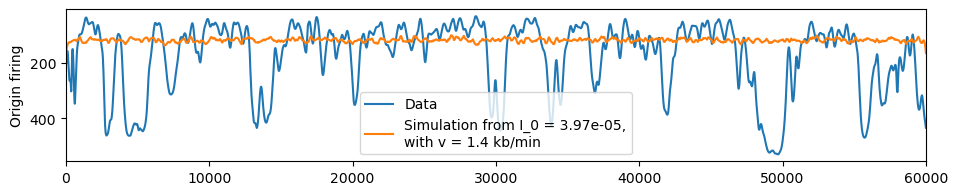

In [23]:
mplotf(
    [
        [replication_timing, replication_timing_sim],
    ],
    mlabels=[
        ["Data", f"Simulation from I_0 = {firing_rate_constant:.2e},\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    minvyQ=[True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "RT (min)"],
    figsize=(10, 1.9),
)

Unsurprisingly, although DNAscape tries to find the optimal $I_0$, the uniform assumption is not strong enough to to infer timing.

### 1.2 Space-dependent initiation $I(x)$

Instead, if may assume a space-dependent initiation rate, $I(x)$, which can be obtained by setting `target_form` to `"space"`

In [24]:
fork_speed = 1.4

firing_rate_space = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "space",
    }
)

Now, `rmap` returns an array where each entry corresponds to a firing rate at each kilobase. Again, we may use this array and the constant fork speed to simulate the replication timing profile.

In [25]:
replication_timing_sim = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
    },
)["replication_timing"]

We may then plot the fitted firing rate profile, with its corresponding timing profile and data reference.

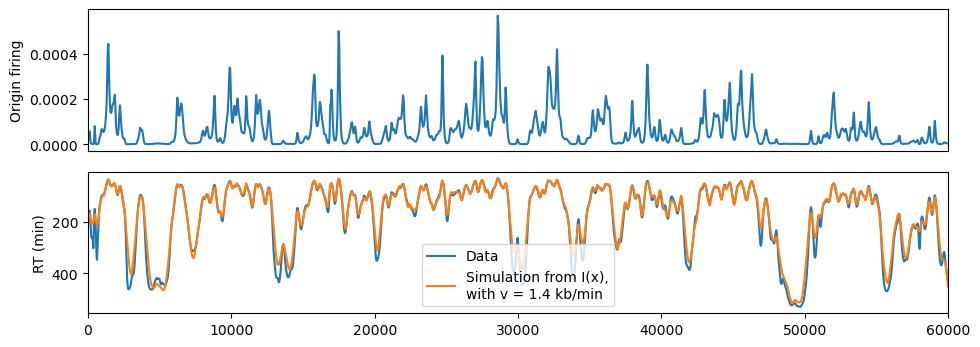

In [26]:
mplotf(
    [
        firing_rate_space,
        [replication_timing, replication_timing_sim],
    ],
    mlabels=[
        None,
        ["Data", f"Simulation from I(x),\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    minvyQ=[False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "RT (min)"],
    figsize=(10, 1.9),
)

### 1.3 Time-dependent initiation $I(t)$

Alternatively, one might assume a model where initiation rate is a time-only feature, with origin firing rates changing only across S phase. In this case, one may `target_form` to `"time"`, while fixing a time discretisation with `resolution_t` (in minutes).

In [30]:
firing_rate_time = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "time",
        "resolution_t": 5,
    }
)

[10/10]  Elapsed: 00:00:12  ETA: 00:00:00  MSE: 5.4191e+02
Refining time-dependent firing rate...


In [28]:
replication_timing_sim_time = rsim(
    source={
        "firing_rate": firing_rate_time,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "interval_kb": interval_kb,
        "resolution_t": 5,
    },
)["replication_timing"]

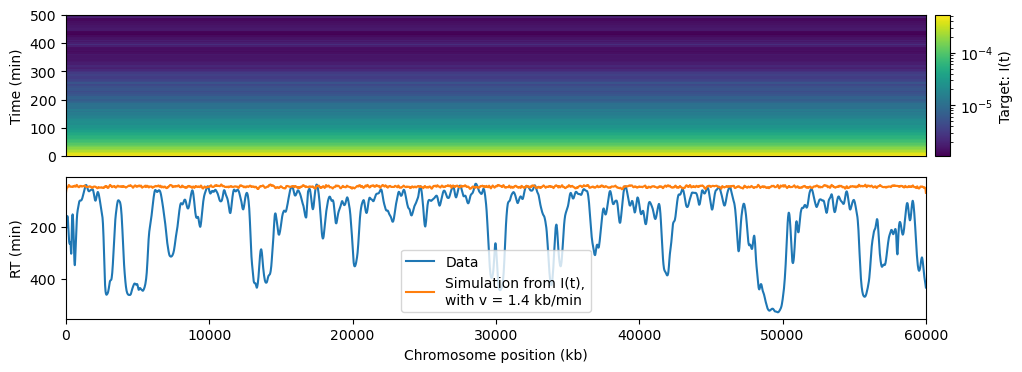

In [29]:
mplotf(
    [
        firing_rate_time,
        [replication_timing, replication_timing_sim_time],
    ],
    mlabels=[
        ["Target: I(t)"],
        ["Data", f"Simulation from I(t),\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 1],
    minvyQ=[False, True],
    mlogzQ=[True, False],
    mxtitle=["", "Chromosome position (kb)"],
    mytitle=["Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

Unlike in the previous section, time-dependent initiation rate and constant fork speed are equally insufficient to match replication timing profiles.

### 1.4 Spacetime-dependent initiation $I(x,t)$

A full space-time initiation field keeps both genomic position and S-phase time explicit. This is the most flexible initiation-only target available, but it may be prone to overfitting and should therefore be used with care. In this case, we set `target_form` to `"spacetime"`.

In [33]:
rmap.requirements(target="firing_rate", explain_assumptions=True)

,assumption,default,description
0,target_form,space,"Requested output form: scalar (constant in space and time), array (space-dependent), transposed array (time-dependent), or matrix (space-time dependent)."
1,resolution_x,1.0,"Spatial resolution along the genome, in kb."
2,resolution_t,1.0,"Temporal resolution, in minutes."
3,time_grid,None,Explicit time axis to use for time-dependent fields.
4,T0,None,Reference start time used when converting timing values to a relative time axis.
5,perQ,False,Whether the genome is treated as periodic/circular.
6,neighbourhood_range,2000,"Spatial range, in kb, used by deterministic neighbourhood mappings."
7,rate_bounds,None,Allowed lower and upper bounds for scalar firing-rate fitting.
8,fit_step,0.6,"Global multiplicative update size for the active fitting phase; fit_step_x, fit_step_t, or fit_step_xt override it for specific phases."
9,maxiter,10,"Global iteration count for the active fitting phase; maxiter_x, maxiter_t, or maxiter_xt override it for specific phases."


In [46]:
firing_rate_spacetime = rmap(
    source={
        "replication_timing": replication_timing,
        "fork_speed": fork_speed,
    },
    target="firing_rate",
    assumptions={
        "target_form": "spacetime",
        "resolution_t": 5,
        "maxiter": 10
    }
)

[10/10]  Elapsed: 00:00:10  ETA: 00:00:00  MSE: 5.4191e+02
Refining space-time firing rate...


In [47]:
replication_timing_sim_spacetime = rsim(
    source={
        "firing_rate": firing_rate_spacetime,
        "fork_speed": fork_speed,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

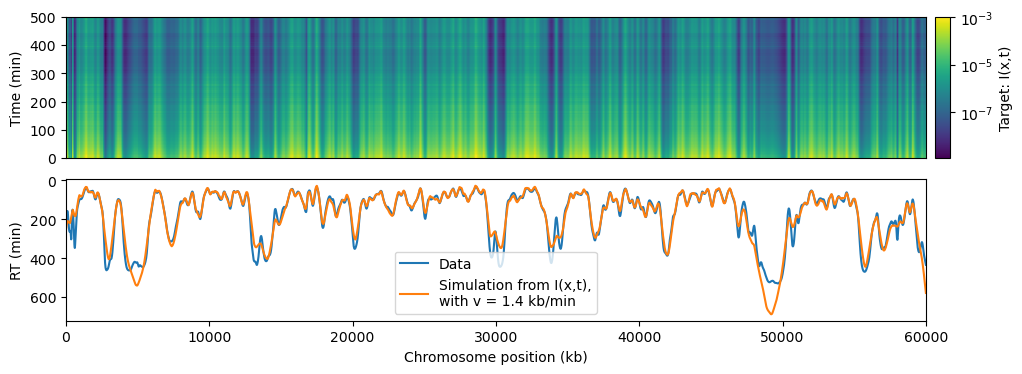

In [48]:
mplotf(
    [
        firing_rate_spacetime,
        [replication_timing, replication_timing_sim_spacetime],
    ],
    mlabels=[
        ["Target: I(x,t)"],
        ["Data", f"Simulation from I(x,t),\nwith v = {fork_speed} kb/min"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 1],
    minvyQ=[False, True],
    mlogzQ=[True, False],
    mxtitle=["", "Chromosome position (kb)"],
    mytitle=["Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

## 2. Target: Fork speed $v(x,t)$

Fork speed can be mapped from replication timing when origin firing is supplied as the second kinetic input. Here we keep timing fixed as the data source and vary the firing-rate form: a uniform rate $I_0$, a spatial profile $I(x)$, or the space-time field $I(x,t)$ estimated above. As in Section 1, `target_form` defines the dependency structure of the inferred fork speed, while the fitting controls are left to the internal defaults.

### 2.1 Uniform initiation $I_0$ to spatial fork speed $v(x)$

With a uniform initiation baseline, `rmap` asks how much regional fork-speed variation is needed to explain the timing profile.

In [19]:
fork_speed_space_from_I0 = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_constant,
    },
    target="fork_speed",
    assumptions={
        "target_form": "space",
    }
)

In [20]:
replication_timing_sim_speed_I0_space = rsim(
    source={
        "firing_rate": firing_rate_constant,
        "fork_speed": fork_speed_space_from_I0,
    },
    assumptions={
        "sim_number": 100,
    },
)["replication_timing"]

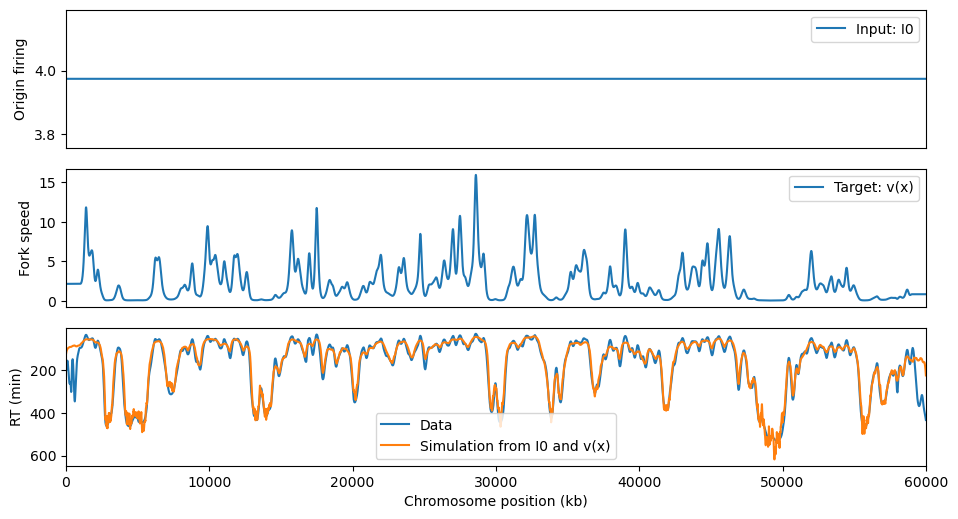

In [21]:
mplotf(
    [
        np.full(n_positions, firing_rate_constant),
        fork_speed_space_from_I0,
        [replication_timing, replication_timing_sim_speed_I0_space],
    ],
    mlabels=[
        ["Input: I0"],
        ["Target: v(x)"],
        ["Data", "Simulation from I0 and v(x)"],
    ],
    mx_array=positions_kb,
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Fork speed", "RT (min)"],
    figsize=(10, 1.9),
)

### 2.2 Spatial initiation $I(x)$ to spatial fork speed $v(x)$

When initiation is already spatially resolved, the fitted speed profile captures the remaining positional structure needed to match timing.

In [22]:
fork_speed_space_from_Ix = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_space,
    },
    target="fork_speed",
    assumptions={
        "target_form": "space",
    }
)

In [23]:
replication_timing_sim_speed_Ix_space = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed_space_from_Ix,
    },
    assumptions={
        "sim_number": 100,
    },
)["replication_timing"]

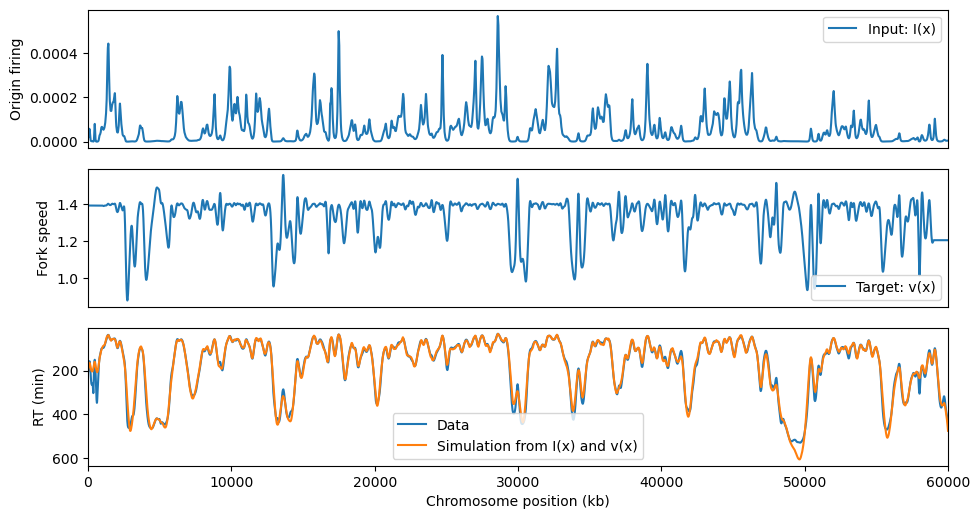

In [24]:
mplotf(
    [
        firing_rate_space,
        fork_speed_space_from_Ix,
        [replication_timing, replication_timing_sim_speed_Ix_space],
    ],
    mlabels=[
        ["Input: I(x)"],
        ["Target: v(x)"],
        ["Data", "Simulation from I(x) and v(x)"],
    ],
    mx_array=positions_kb,
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Fork speed", "RT (min)"],
    figsize=(10, 1.9),
)

### 2.3 Spatial initiation $I(x)$ to time-dependent fork speed $v(t)$

This route compresses the spatial speed fit onto the S-phase time coordinate and refines the temporal profile internally.

In [25]:
fork_speed_time_from_Ix = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_space,
    },
    target="fork_speed",
    assumptions={
        "target_form": "time",
        "resolution_t": 5,
    }
)

In [26]:
replication_timing_sim_speed_Ix_time = rsim(
    source={
        "firing_rate": firing_rate_space,
        "fork_speed": fork_speed_time_from_Ix,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

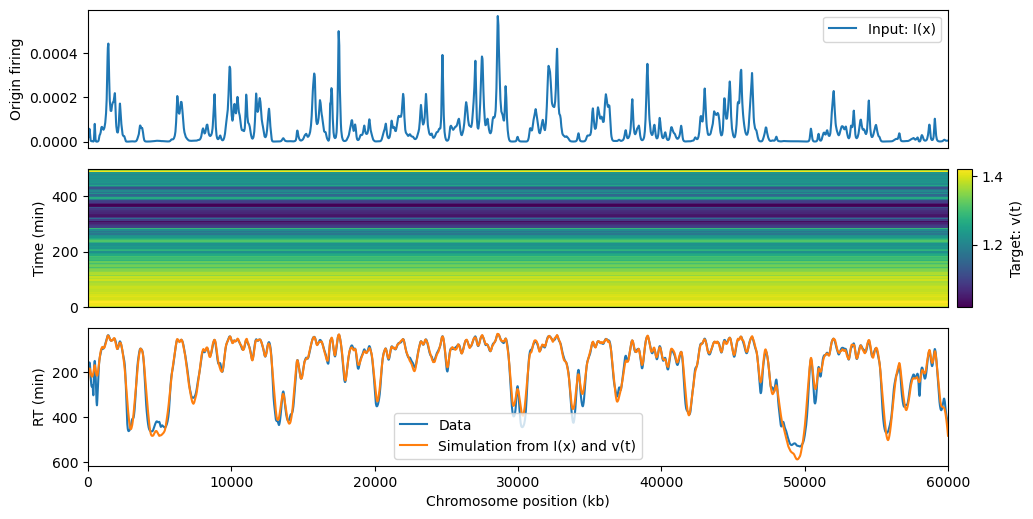

In [27]:
mplotf(
    [
        firing_rate_space,
        fork_speed_time_from_Ix,
        [replication_timing, replication_timing_sim_speed_Ix_time],
    ],
    mlabels=[
        ["Input: I(x)"],
        ["Target: v(t)"],
        ["Data", "Simulation from I(x) and v(t)"],
    ],
    mx_array=positions_kb,
    mresolution_t=[1, 5, 1],
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

### 2.4 Space-time initiation $I(x,t)$ to space-time fork speed $v(x,t)$

The most general one-target speed fit keeps both axes explicit, returning a space-time fork-speed field from timing and $I(x,t)$.

In [28]:
fork_speed_spacetime_from_Ixt = rmap(
    source={
        "replication_timing": replication_timing,
        "firing_rate": firing_rate_spacetime,
    },
    target="fork_speed",
    assumptions={
        "target_form": "spacetime",
        "resolution_t": 5,
    }
)

In [29]:
replication_timing_sim_speed_Ixt_spacetime = rsim(
    source={
        "firing_rate": firing_rate_spacetime,
        "fork_speed": fork_speed_spacetime_from_Ixt,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

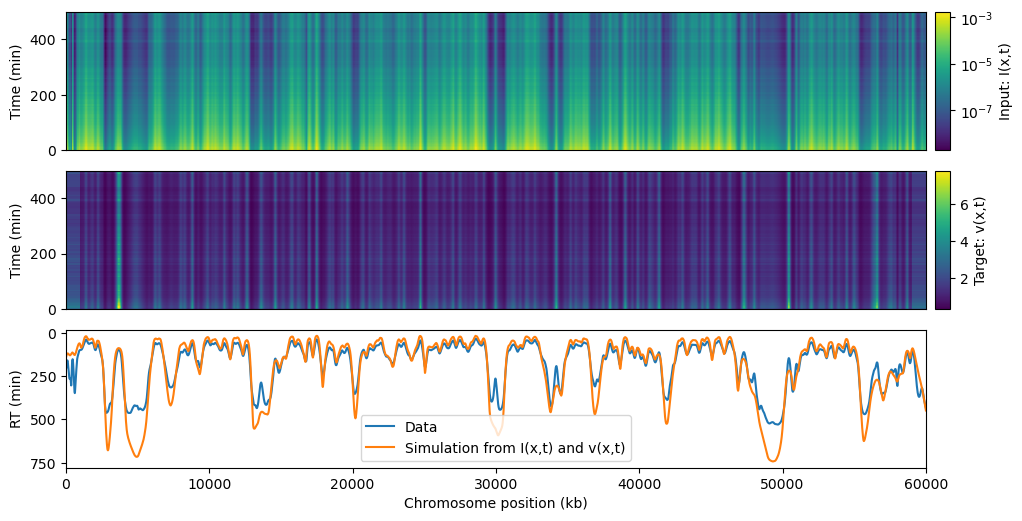

In [30]:
mplotf(
    [
        firing_rate_spacetime,
        fork_speed_spacetime_from_Ixt,
        [replication_timing, replication_timing_sim_speed_Ixt_spacetime],
    ],
    mlabels=[
        ["Input: I(x,t)"],
        ["Target: v(x,t)"],
        ["Data", "Simulation from I(x,t) and v(x,t)"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 5, 1],
    minvyQ=[False, False, True],
    mlogzQ=[True, False, False],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Time (min)", "Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

## 3. Target: joint kinetic fields $I(x,t)$ and $v(x,t)$

This route uses replication timing alone to fit initiation and fork-speed fields simultaneously. It is different from first estimating $I(x,t)$ and then fitting $v(x,t)$: both fields are updated together from the same timing residual, giving one compatible kinetic decomposition of the data. The solution is not unique, and the flexibility of two full space-time fields can naturally overfit timing; the point here is to showcase the most expressive mapping option when that flexibility is useful.

In [35]:
joint_kinetics = rmap(
    source={
        "replication_timing": replication_timing,
    },
    target="kinetic_fields",
    assumptions={
        "target_form": "spacetime",
        "resolution_t": 5,
        "maxiter": 20,
    },
)

firing_rate_joint = joint_kinetics["firing_rate"]
fork_speed_joint = joint_kinetics["fork_speed"]
joint_kinetics["fit_history"]

array([4770.80519936, 1948.24483886,  991.21139268, 1008.48767846,
       1216.04177228,  524.69873482,  820.37398424,  838.30679822,
        688.97869366,  463.27161266,  521.82985049,  546.67011799,
        756.71679277,  413.65486006,  450.33508338,  462.19194602,
        509.70784693,  457.04664651,  439.526419  ,  513.0621424 ])

The fitted fields can be sent directly to `rsim`. The timing row below compares the original RT data with a stochastic simulation driven by the jointly fitted kinetics.

In [36]:
replication_timing_sim_joint = rsim(
    source={
        "firing_rate": firing_rate_joint,
        "fork_speed": fork_speed_joint,
    },
    assumptions={
        "sim_number": 100,
        "resolution_t": 5,
    },
)["replication_timing"]

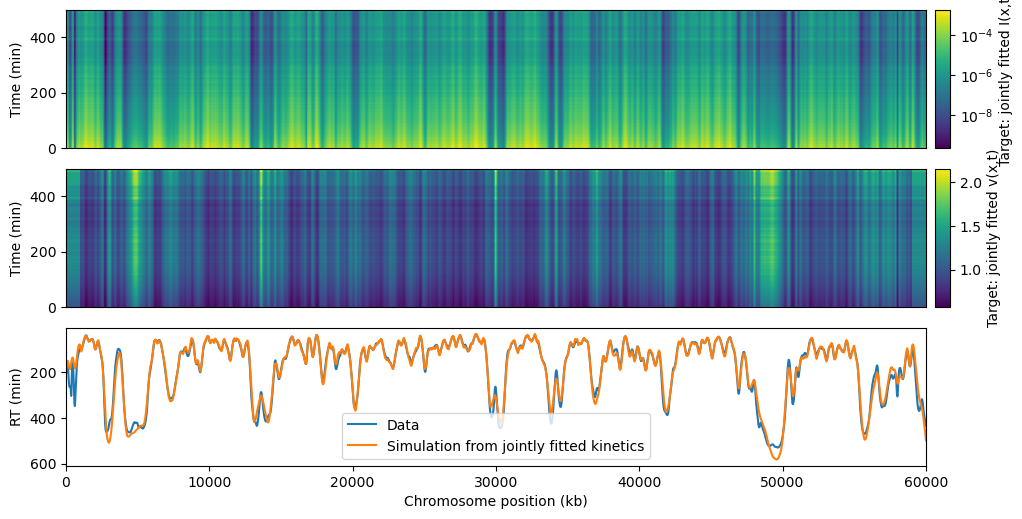

In [37]:
mplotf(
    [
        firing_rate_joint,
        fork_speed_joint,
        [replication_timing, replication_timing_sim_joint],
    ],
    mlabels=[
        ["Target: jointly fitted I(x,t)"],
        ["Target: jointly fitted v(x,t)"],
        ["Data", "Simulation from jointly fitted kinetics"],
    ],
    mx_array=positions_kb,
    mresolution_t=[5, 5, 1],
    minvyQ=[False, False, True],
    mlogzQ=[True, False, False],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Time (min)", "Time (min)", "RT (min)"],
    figsize=(10, 1.9),
)

## 4. Target: replication timing

Use this target when firing and fork speed are supplied and the goal is a predicted timing profile.

### 4.1 I0 and v0 to timing

A scalar firing rate needs `interval_kb` so DNAscape knows the length of the returned profile.

In [ ]:
constant_timing_fit = rmap(
    source={
        "firing_rate": fitted_I0,
        "fork_speed": fitted_v0_from_I0,
    },
    target="replication_timing",
    assumptions={
        "resolution_x": output_resolution_kb,
        "interval_kb": interval_kb,
    },
    return_info=True,
)

timing_from_I0 = constant_timing_fit["values"]
sim_timing_from_I0 = rsim(
    source={
        "firing_rate": fitted_I0,
        "fork_speed": fitted_v0_from_I0,
    },
    assumptions={
        "sim_number": simulation_replicates,
        "resolution_x": output_resolution_kb,
        "interval_kb": interval_kb,
        "seed": 31,
        "verbose": False,
    },
)["replication_timing"]

print(constant_timing_fit["method"], timing_from_I0.shape)

NameError: name 'fitted_I0' is not defined

In [ ]:
mplotf(
    [
        np.full(n_positions, fitted_I0),
        np.full(n_positions, fitted_v0_from_I0),
        [replication_timing, timing_from_I0, sim_timing_from_I0],
    ],
    mlabels=[
        ["Input: fitted I0"],
        ["Input: fitted v0"],
        ["Reference: timing data", "Target: timing from I0", "rsim: I0 + v0"],
    ],
    mx_array=[positions_kb, positions_kb, positions_kb],
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Fork speed", "Replication timing (min)"],
    figsize=(10, 1.9),
    hspace=0.16,
)

### 4.2 I(x) and v0 to timing

The spatial firing profile maps forward to a timing profile over the same genomic bins.

In [ ]:
spatial_timing_fit = rmap(
    source={
        "firing_rate": firing_rate,
        "fork_speed": fitted_v0_from_Ix,
    },
    target="replication_timing",
    assumptions={
        "resolution_x": output_resolution_kb,
    },
    return_info=True,
)

timing_from_Ix = spatial_timing_fit["values"]
sim_timing_from_Ix = rsim(
    source={
        "firing_rate": firing_rate,
        "fork_speed": fitted_v0_from_Ix,
    },
    assumptions={
        "sim_number": simulation_replicates,
        "resolution_x": output_resolution_kb,
        "interval_kb": interval_kb,
        "seed": 32,
        "verbose": False,
    },
)["replication_timing"]

print(spatial_timing_fit["method"], timing_from_Ix.shape)

In [ ]:
mplotf(
    [
        firing_rate,
        np.full(n_positions, fitted_v0_from_Ix),
        [replication_timing, timing_from_Ix, sim_timing_from_Ix],
    ],
    mlabels=[
        ["Input: fitted I(x)"],
        ["Input: fitted v0"],
        ["Reference: timing data", "Target: timing from I(x)", "rsim: I(x) + v0"],
    ],
    mx_array=[positions_kb, positions_kb, positions_kb],
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=["Origin firing", "Fork speed", "Replication timing (min)"],
    figsize=(10, 1.9),
    hspace=0.16,
)

## 5. Combined view

This final panel compares the constant and spatial routes on the same interval.

In [ ]:
mplotf(
    [
        [np.full(n_positions, fitted_I0), firing_rate],
        [np.full(n_positions, fitted_v0_from_I0), np.full(n_positions, fitted_v0_from_Ix)],
        [replication_timing, timing_from_I0, timing_from_Ix, sim_timing_from_I0, sim_timing_from_Ix],
    ],
    mlabels=[
        ["Fitted I0", "Fitted I(x)"],
        ["v0 from I0", "v0 from I(x)"],
        ["Timing data", "Timing from I0", "Timing from I(x)", "rsim: I0 + v0", "rsim: I(x) + v0"],
    ],
    mx_array=[positions_kb, positions_kb, positions_kb],
    minvyQ=[False, False, True],
    mxtitle=["", "", "Chromosome position (kb)"],
    mytitle=[
        "Firing rate",
        "Fork speed",
        "Replication timing (min)",
    ],
    figsize=(10, 2.3),
    hspace=0.18,
)